# Movie Recommender System

## Project goal
The goal of this project is to build a **recommender system** for movies. Given a few movies that a user has rated, the system suggests other movies that the user will probably like.

The data is from **MovieLens**, collected by GroupLens Research at the University of Minnesota, and has two files:

| File | Column | Meaning |
|---|---|---|
| `movies.csv` | `movieId` | ID of the movie |
| | `title` | Title of the movie (with its release year) |
| | `genres` | Genres of the movie, separated by `|` |
| `ratings_sample.csv.gz` | `userId` | ID of the user |
| | `movieId` | ID of the movie the user rated |
| | `rating` | The score the user gave (0.5 to 5) |
| | `timestamp` | The exact time the rating was saved |

We build **two** recommenders and look at their results side by side:

1. **Content-Based Filtering** looks at the *content* of the movies (their genres). It learns which genres the user likes and recommends movies with those genres.
2. **Collaborative Filtering (User-User)** looks at *other users*. It finds users whose ratings are similar to our user's and recommends movies that those users liked.

### Notebook outline
1. Import libraries and load the data
2. Get to know the data
3. Data preprocessing
4. Exploratory data analysis (charts)
5. Creating the input user
6. Part 1: Content-Based recommender
7. Part 2: Collaborative Filtering recommender
8. Comparing the two results
9. Conclusion

## 1. Import libraries and load the data

* **pandas** for working with tables (DataFrames)
* **numpy** for numerical operations
* **matplotlib** for drawing charts

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Show more columns when printing wide tables
pd.set_option('display.max_columns', 30)

This project uses exactly the same two files as lessons 15 and 16, so instead of keeping a third copy of them, the notebook reads them from lesson 15's `data/` folder. The ratings file is gzip-compressed (26 MB instead of 102 MB); pandas reads it directly.

In [2]:
from pathlib import Path

# The data is shared with lessons 15 and 16, so it is read from lesson 15's folder
DATA_DIR = Path('../../lessons/15-content-based-recommender/data')

movies_df = pd.read_csv(DATA_DIR / 'movies.csv')
ratings_df = pd.read_csv(DATA_DIR / 'ratings_sample.csv.gz')

## 2. Get to know the data

### 2.1 Movies

In [3]:
# First 5 rows of the movies table
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
# (number of rows, number of columns)
print('Movies table shape:', movies_df.shape)
# Column types and non-empty counts
movies_df.info()

Movies table shape: (34208, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34208 entries, 0 to 34207
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  34208 non-null  int64 
 1   title    34208 non-null  object
 2   genres   34208 non-null  object
dtypes: int64(1), object(2)
memory usage: 801.9+ KB


Each row is one movie. The `title` contains the release year in parentheses, and `genres` holds several genres in one text field, separated by `|`.

### 2.2 Ratings

In [5]:
# First 5 rows of the ratings table
ratings_df.head()

,userId,movieId,rating,timestamp
0,1,169,2.5,1204927694
1,1,2471,3.0,1204927438
2,1,48516,5.0,1204927435
3,2,2571,3.5,1436165433
4,2,109487,4.0,1436165496


In [6]:
print('Ratings table shape:', ratings_df.shape)
ratings_df.info()

Ratings table shape: (3899999, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3899999 entries, 0 to 3899998
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 119.0 MB


Each row is one rating: user `userId` gave the movie `movieId` a score of `rating`. Let's count how many users and movies we have, and look at basic statistics of the ratings.

In [7]:
print('Number of ratings :', len(ratings_df))
print('Number of users   :', ratings_df['userId'].nunique())
print('Number of movies  :', ratings_df['movieId'].nunique())

# count, mean, standard deviation, min, quartiles and max of the rating column
ratings_df['rating'].describe()

Number of ratings : 3899999
Number of users   : 42130
Number of movies  : 23648


count    3.899999e+06
mean     3.520976e+00
std      1.066426e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

### 2.3 Missing values and duplicates
Before using the data, we check that there are no empty cells and no repeated rows.

In [8]:
print('Missing values in movies :')
print(movies_df.isnull().sum(), '\n')
print('Missing values in ratings:')
print(ratings_df.isnull().sum(), '\n')

print('Duplicate rows in movies :', movies_df.duplicated().sum())
print('Duplicate rows in ratings:', ratings_df.duplicated().sum())

Missing values in movies :
movieId    0
title      0
genres     0
dtype: int64 

Missing values in ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64 

Duplicate rows in movies : 0
Duplicate rows in ratings: 0


## 3. Data preprocessing

### 3.1 Separate the year from the title
The title looks like `Toy Story (1995)`. We move the year into its own `year` column and keep only the name in `title`. This makes it easy to search for a movie by its name.

* `str.extract` with the pattern `\((\d{4})\)` finds 4 digits inside parentheses and copies them out.
* `str.replace` removes the `(1995)` part from the title. `regex=True` tells pandas the pattern is a regular expression.
* `str.strip` removes the space left at the end.

In [9]:
# Copy the year out of the title (first, while it is still there)
movies_df['year'] = movies_df['title'].str.extract(r'\((\d{4})\)', expand=False)

# Remove the '(YYYY)' part from the title, then remove leftover spaces
movies_df['title'] = movies_df['title'].str.replace(r'\(\d{4}\)', '', regex=True).str.strip()

movies_df.head()

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995


### 3.2 Turn genres into columns (One-Hot Encoding)
A computer cannot do math with text like `Adventure|Comedy`. So we create **one column per genre**: the value is **1** if the movie has that genre and **0** if not. This is called *one-hot encoding*.

`str.get_dummies(sep='|')` does this in one step: it splits the text at every `|` and builds the 0/1 columns.

In [10]:
# One 0/1 column for every genre
genres_df = movies_df['genres'].str.get_dummies(sep='|')

# '(no genres listed)' is not a real genre, so we remove it
genres_df = genres_df.drop(columns='(no genres listed)', errors='ignore')

# Keep the list of genre names for later
genre_names = genres_df.columns.tolist()
print('Number of genres:', len(genre_names))
print(genre_names)

# Put the movie information and the genre columns side by side
moviesWithGenres_df = pd.concat([movies_df, genres_df], axis=1)
moviesWithGenres_df.head()

Number of genres: 19
['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'IMAX', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']


,movieId,title,genres,year,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji,Adventure|Children|Fantasy,1995,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men,Comedy|Romance,1995,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II,Comedy,1995,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 3.3 Drop the timestamp
Our recommenders only need *who* rated *what* and *how much*. The time of the rating is not used, so we drop the `timestamp` column to save memory.

In [11]:
ratings_df = ratings_df.drop(columns='timestamp')
ratings_df.head()

,userId,movieId,rating
0,1,169,2.5
1,1,2471,3.0
2,1,48516,5.0
3,2,2571,3.5
4,2,109487,4.0


## 4. Exploratory data analysis
Charts help us understand the data before building the recommenders.

### 4.1 How are the ratings distributed?

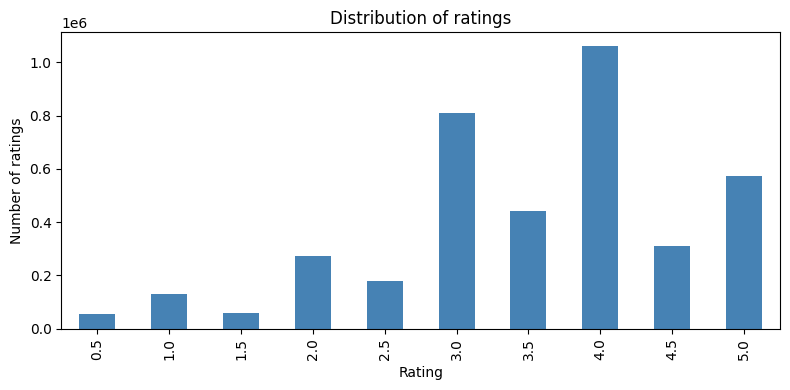

In [12]:
# Count how many times each rating value was given
rating_counts = ratings_df['rating'].value_counts().sort_index()

rating_counts.plot(kind='bar', figsize=(8, 4), color='steelblue')
plt.title('Distribution of ratings')
plt.xlabel('Rating')
plt.ylabel('Number of ratings')
plt.tight_layout()
plt.show()

Most ratings are 3, 4 or higher, and whole numbers (3, 4, 5) are more common than half numbers. In general, people rate movies they liked more often than movies they didn't like.

### 4.2 Which genres are the most common?

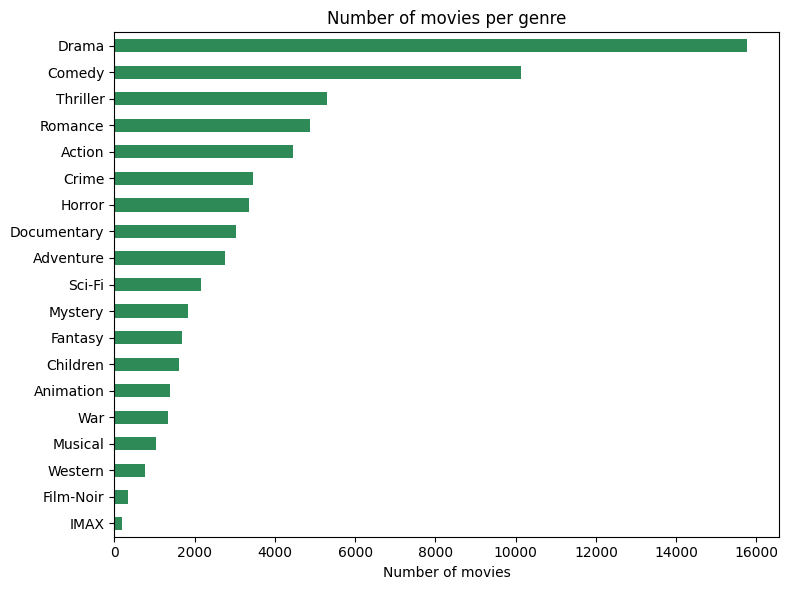

In [13]:
# Summing each 0/1 column gives the number of movies in that genre
genre_counts = genres_df.sum().sort_values()

genre_counts.plot(kind='barh', figsize=(8, 6), color='seagreen')
plt.title('Number of movies per genre')
plt.xlabel('Number of movies')
plt.tight_layout()
plt.show()

Drama and Comedy are by far the most common genres. Genres like Film-Noir and IMAX are rare.

### 4.3 How many ratings does each user give?

count    42130.000000
mean        92.570591
std        192.454383
min          1.000000
25%         15.000000
50%         29.000000
75%         89.000000
max       5691.000000
dtype: float64


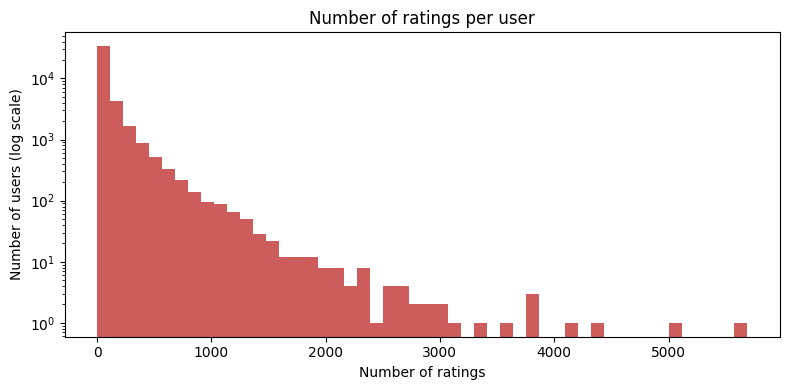

In [14]:
# Number of ratings given by each user
ratings_per_user = ratings_df.groupby('userId').size()
print(ratings_per_user.describe())

ratings_per_user.plot(kind='hist', bins=50, figsize=(8, 4), color='indianred', log=True)
plt.title('Number of ratings per user')
plt.xlabel('Number of ratings')
plt.ylabel('Number of users (log scale)')
plt.tight_layout()
plt.show()

Most users rate a small number of movies, and a few users rate a very large number. Because of this, the user–movie table is very **sparse**: each user has seen only a tiny part of all the movies. This is why we need recommender systems.

### 4.4 Most rated and best rated movies

In [15]:
# For every movie: number of ratings and average rating
movie_stats = ratings_df.groupby('movieId')['rating'].agg(num_ratings='count', avg_rating='mean')
movie_stats = movie_stats.merge(movies_df[['movieId', 'title', 'year']], on='movieId')

# The 10 movies with the most ratings
movie_stats.sort_values('num_ratings', ascending=False).head(10)

,movieId,num_ratings,avg_rating,title,year
352,356,13848,4.050116,Forrest Gump,1994
293,296,13488,4.162811,Pulp Fiction,1994
315,318,13234,4.442837,"Shawshank Redemption, The",1994
587,593,12912,4.156366,"Silence of the Lambs, The",1991
476,480,11887,3.646841,Jurassic Park,1993
257,260,11393,4.160669,Star Wars: Episode IV - A New Hope,1977
2485,2571,11035,4.167739,"Matrix, The",1999
108,110,10501,4.038425,Braveheart,1995
0,1,10319,3.886181,Toy Story,1995
523,527,10269,4.287467,Schindler's List,1993


A movie with only one rating of 5 would have a perfect average, but one opinion is not enough. So for the "best rated" list we only consider movies that are in the **top 10% by number of ratings**.

In [16]:
# Minimum number of ratings: the 90th percentile
min_ratings = movie_stats['num_ratings'].quantile(0.90)
print('Minimum number of ratings:', min_ratings)

popular_movies = movie_stats[movie_stats['num_ratings'] >= min_ratings]
popular_movies.sort_values('avg_rating', ascending=False).head(10)

Minimum number of ratings: 310.2999999999993


,movieId,num_ratings,avg_rating,title,year
315,318,13234,4.442837,"Shawshank Redemption, The",1994
843,858,8470,4.349646,"Godfather, The",1972
49,50,9092,4.318852,"Usual Suspects, The",1995
523,527,10269,4.287467,Schindler's List,1993
1935,2019,2138,4.275959,Seven Samurai (Shichinin no samurai),1954
1195,1221,5461,4.247391,"Godfather: Part II, The",1974
2872,2959,8316,4.243206,Fight Club,1999
887,904,3326,4.240980,Rear Window,1954
1169,1193,6132,4.231164,One Flew Over the Cuckoo's Nest,1975
895,912,4714,4.228893,Casablanca,1942


This "best rated movies" list is the same for everyone, so it isn't personal. The two recommenders below build a **personal** list for one user.

## 5. Creating the input user
This is the user we want to recommend movies to. We write down some movies they have watched and the rating they gave each one.

**Notes:**
* The title must be written as it appears in the dataset, for example `'Matrix, The'` for "The Matrix".
* You can add or remove movies to test the system with a different taste.

In [17]:
userInput = [
    {'title': 'Matrix, The',      'rating': 5.0},
    {'title': 'Inception',        'rating': 4.5},
    {'title': 'Godfather, The',   'rating': 4.0},
    {'title': 'Forrest Gump',     'rating': 4.0},
    {'title': 'Lion King, The',   'rating': 3.0},
    {'title': 'Notebook, The',    'rating': 1.5},
]
inputMovies = pd.DataFrame(userInput)
inputMovies

,title,rating
0,"Matrix, The",5.0
1,Inception,4.5
2,"Godfather, The",4.0
3,Forrest Gump,4.0
4,"Lion King, The",3.0
5,"Notebook, The",1.5


### 5.1 Add the movieId to the input
The ratings file uses `movieId`, not titles, so we look up the ID of every input movie by **merging** the input with the movies table on the `title` column. If a movie can't be found, we print its title so it can be checked.

In [18]:
# Merge on 'title' to get each movie's movieId
inputMovies = inputMovies.merge(movies_df[['movieId', 'title']], on='title', how='left')

# Some titles exist more than once (remakes); keep only the first match
inputMovies = inputMovies.drop_duplicates(subset='title')

# Show titles that were not found in the dataset, then remove them
not_found = inputMovies[inputMovies['movieId'].isnull()]['title'].tolist()
if not_found:
    print('Not found in the dataset:', not_found)
inputMovies = inputMovies.dropna(subset=['movieId'])
inputMovies['movieId'] = inputMovies['movieId'].astype(int)

inputMovies = inputMovies[['movieId', 'title', 'rating']].reset_index(drop=True)
inputMovies

,movieId,title,rating
0,2571,"Matrix, The",5.0
1,79132,Inception,4.5
2,858,"Godfather, The",4.0
3,356,Forrest Gump,4.0
4,364,"Lion King, The",3.0
5,8533,"Notebook, The",1.5


## 6. Part 1: Content-Based recommender

**Idea:** if the user gave high ratings to Sci-Fi movies, they probably like Sci-Fi, so we recommend other Sci-Fi movies.

Steps:
1. Take the genre table of the movies the user watched.
2. Build a **user profile**: how much the user likes each genre.
3. Give every movie in the dataset a score based on the user profile.
4. Recommend the movies with the highest scores.

### 6.1 Genre table of the watched movies

In [19]:
# Rows of the genre table that belong to the input movies, with the user's rating attached
userMovies = inputMovies[['movieId', 'rating']].merge(moviesWithGenres_df, on='movieId')

# Keep only the 0/1 genre columns
userGenreTable = userMovies[genre_names]
userGenreTable

,Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0
1,1,0,0,0,0,1,0,1,0,0,0,1,0,1,0,1,1,0,0
2,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0
4,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0
5,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0


### 6.2 Build the user profile
The user profile tells us how much the user likes each genre.

**Step 1: center the ratings.** We subtract the user's average rating from each rating. A movie rated *above* the user's average gets a positive value ("liked"), and a movie rated *below* average gets a negative value ("disliked"). For example, The Notebook (1.5) becomes negative, so its genres (Drama, Romance) lose weight.

**Step 2: add up per genre.** For each genre, we add up the centered ratings of the watched movies that have that genre. This is a **dot product** between the genre table (transposed: genres × movies) and the vector of centered ratings.

In [20]:
# Step 1: centered rating = rating - the user's average rating
userMovies['centeredRating'] = userMovies['rating'] - userMovies['rating'].mean()
userMovies[['title', 'rating', 'centeredRating']]

,title,rating,centeredRating
0,"Matrix, The",5.0,1.333333
1,Inception,4.5,0.833333
2,"Godfather, The",4.0,0.333333
3,Forrest Gump,4.0,0.333333
4,"Lion King, The",3.0,-0.666667
5,"Notebook, The",1.5,-2.166667


In [21]:
# Step 2: weight of each genre = sum of the centered ratings of the movies that have it
userProfile = userGenreTable.T.dot(userMovies['centeredRating'])
userProfile.sort_values(ascending=False, kind='stable')

Action         2.166667
Sci-Fi         2.166667
Thriller       2.166667
Crime          1.166667
Mystery        0.833333
Comedy         0.333333
War            0.333333
IMAX           0.166667
Documentary    0.000000
Fantasy        0.000000
Film-Noir      0.000000
Horror         0.000000
Western        0.000000
Adventure     -0.666667
Animation     -0.666667
Children      -0.666667
Musical       -0.666667
Drama         -1.333333
Romance       -1.833333
dtype: float64

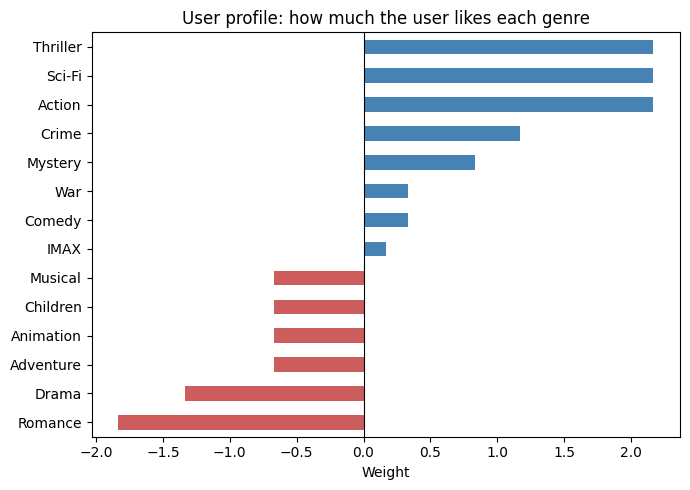

In [22]:
# Genres with weight 0 are hidden; blue = liked, red = disliked
profile_plot = userProfile[userProfile != 0].sort_values()
colors = ['steelblue' if w > 0 else 'indianred' for w in profile_plot]
profile_plot.plot(kind='barh', figsize=(7, 5), color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('User profile: how much the user likes each genre')
plt.xlabel('Weight')
plt.tight_layout()
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

### 6.3 Score every movie (cosine similarity)
We compare every movie's genre vector with the user profile using **cosine similarity**:

$$
\text{score} = \frac{\text{movie} \cdot \text{profile}}{\lVert \text{movie} \rVert \times \lVert \text{profile} \rVert}
$$

* The top part (dot product) adds up the profile weights of the genres the movie has.
* The bottom part divides by the length of the two vectors. Because of this, a movie doesn't get a high score just because it lists many genres. What matters is how well its genres *match* the profile.

The score is between -1 and 1: close to 1 means the genres match the user's taste very well, and a negative score means the movie is mostly made of genres the user dislikes.

In [23]:
# Genre table of all the movies, with movieId as the row label
genreTable = moviesWithGenres_df.set_index('movieId')[genre_names]

# Top part: dot product of every movie with the profile
dot_product = genreTable.dot(userProfile)

# Bottom part: length of every movie vector x length of the profile vector
movie_length = np.sqrt((genreTable ** 2).sum(axis=1))
profile_length = np.sqrt((userProfile ** 2).sum())

# Movies with no genres have length 0; dividing gives NaN, which we set to 0
content_scores = (dot_product / (movie_length * profile_length)).fillna(0)
content_scores.head()

movieId
1   -0.154395
2   -0.159459
3   -0.219708
4   -0.338850
5    0.069048
dtype: float64

### 6.4 Top 10 content-based recommendations
* Movies the user has already watched are removed.
* We only recommend movies that are in the top 10% by number of ratings (the same `min_ratings` as in section 4.4). The dataset has many unknown movies with very few ratings; this rule keeps the list to movies that enough people have seen.
* Many movies have exactly the same genres, so they get the same score. When scores are equal, the movie with **more ratings** comes first.

In [24]:
# Put the scores in a table and add the number of ratings of each movie
content_rec = content_scores.rename('score').reset_index()
content_rec = content_rec.merge(movie_stats[['movieId', 'num_ratings']], on='movieId', how='left')
content_rec['num_ratings'] = content_rec['num_ratings'].fillna(0).astype(int)

# Remove the movies the user has already watched, and keep only well-known movies
content_rec = content_rec[~content_rec['movieId'].isin(inputMovies['movieId'])]
content_rec = content_rec[content_rec['num_ratings'] >= min_ratings]

# Sort by score, then by number of ratings
content_rec = content_rec.sort_values(['score', 'num_ratings'], ascending=False)

# Add title, year and genres, and show the top 10
content_top10 = content_rec.head(10).merge(movies_df, on='movieId', how='left')
content_top10[['title', 'year', 'genres', 'score', 'num_ratings']]

,title,year,genres,score,num_ratings
0,RoboCop 2,1990,Action|Crime|Sci-Fi|Thriller,0.794048,951
1,Minority Report,2002,Action|Crime|Mystery|Sci-Fi|Thriller,0.787416,4697
2,"X-Files: Fight the Future, The",1998,Action|Crime|Mystery|Sci-Fi|Thriller,0.787416,2317
3,"Terminator, The",1984,Action|Sci-Fi|Thriller,0.777361,6138
4,Blade Runner,1982,Action|Sci-Fi|Thriller,0.777361,5724
5,Predator,1987,Action|Sci-Fi|Thriller,0.777361,2656
6,Johnny Mnemonic,1995,Action|Sci-Fi|Thriller,0.777361,2412
7,Godzilla,1998,Action|Sci-Fi|Thriller,0.777361,1504
8,Equilibrium,2002,Action|Sci-Fi|Thriller,0.777361,1396
9,X-Men: The Last Stand,2006,Action|Sci-Fi|Thriller,0.777361,1338


The recommended movies share the genres that the user rated highly (from The Matrix and Inception: Action, Sci-Fi, Thriller), and none of them is a Romance, the genre of The Notebook, which the user disliked. The system only looks at genres, so it doesn't know whether a movie is actually good. It only knows that the genres match.

## 7. Part 2: Collaborative Filtering recommender (User-User)

**Idea:** find users who rated the same movies in a similar way to our user. These users are the **neighbours**. Movies that the neighbours liked, and our user hasn't watched, are recommended.

Steps:
1. Find the users who watched the same movies as the input user.
2. Measure how similar each of them is to the input user (Pearson correlation).
3. Pick the most similar users.
4. Use their ratings to give every movie a score, and recommend the best ones.

### 7.1 Users who watched the same movies

In [25]:
# Ratings of the input movies given by other users
userSubset = ratings_df[ratings_df['movieId'].isin(inputMovies['movieId'])]

# Number of input movies each user has rated
common_counts = userSubset.groupby('userId').size()
print('Users who rated at least one input movie:', len(common_counts))
common_counts.value_counts().sort_index()

Users who rated at least one input movie: 21525


1    8253
2    6696
3    3611
4    2132
5     689
6     144
Name: count, dtype: int64

To compare two users we need several movies they both rated. We keep users who rated **at least 4** of the input movies. With few common movies, the similarity value is not reliable: with 2 movies the correlation is always +1 or -1, and with 3 movies many users get a perfect 1.0 just by chance.

In [26]:
MIN_COMMON = 4

selected_users = common_counts[common_counts >= MIN_COMMON].index
userSubset = userSubset[userSubset['userId'].isin(selected_users)]
print('Users kept:', len(selected_users))

Users kept: 2965


### 7.2 Similarity between users (Pearson correlation)
The **Pearson correlation coefficient** measures how similarly two users rate the same movies:

$$
r = \frac{\sum (x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum (x_i-\bar{x})^2}\;\sqrt{\sum (y_i-\bar{y})^2}}
$$

where $x_i$ and $y_i$ are the two users' ratings of the same movie.

* **r = 1**: the users have the same taste
* **r = 0**: no relation
* **r = -1**: opposite taste

Pearson is useful because it doesn't care whether a user rates generously or strictly. It only looks at whether the two users *rise and fall together*.

To compute it, we build a table with **one row per user and one column per input movie** (`pivot`). Then `corrwith` computes the Pearson correlation of every row with the input user's ratings.

In [27]:
# Table: rows = users, columns = input movies, values = ratings (empty if not rated)
userMatrix = userSubset.pivot(index='userId', columns='movieId', values='rating')
userMatrix.head()

movieId,356,364,858,2571,8533,79132
userId,,,,,,
17,5.0,4.0,2.0,5.0,NaN,NaN
37,5.0,4.5,NaN,1.0,0.5,NaN
59,3.5,4.5,NaN,4.5,2.0,5.0
75,3.5,4.0,4.5,4.5,NaN,NaN
106,4.0,3.5,NaN,4.0,NaN,2.5


In [28]:
# The input user's ratings, labelled by movieId (same labels as the table columns)
inputRatings = inputMovies.set_index('movieId')['rating']

# Pearson correlation of every user with the input user
# (np.errstate hides a NumPy warning for users whose correlation can't be computed)
with np.errstate(divide='ignore', invalid='ignore'):
    similarity = userMatrix.corrwith(inputRatings, axis=1)

# A user who gave the same rating to every movie has no correlation (NaN), so we remove them
similarity = similarity.dropna()

pearson_df = similarity.rename('similarity').reset_index()
pearson_df.head()

,userId,similarity
0,17,0.288675
1,37,0.203845
2,59,0.800006
3,75,0.426401
4,106,0.000000


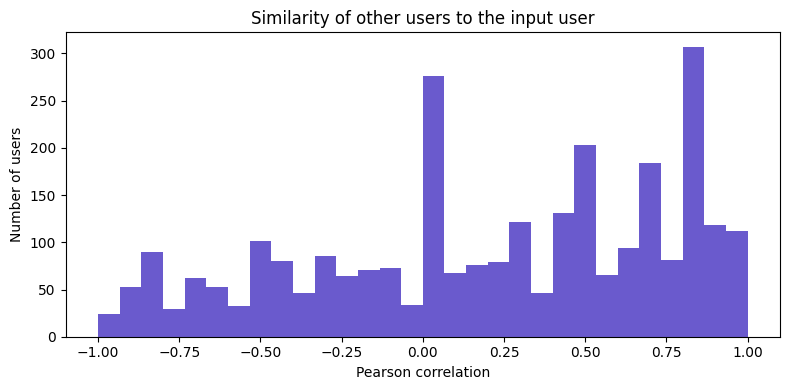

In [29]:
pearson_df['similarity'].plot(kind='hist', bins=30, figsize=(8, 4), color='slateblue')
plt.title('Similarity of other users to the input user')
plt.xlabel('Pearson correlation')
plt.ylabel('Number of users')
plt.tight_layout()
plt.show()

### 7.3 The 50 most similar users (neighbours)
We sort the users by similarity and keep the top 50. Only users with a **positive** similarity are used, because a user with opposite taste is not a good guide.

In [30]:
topUsers = pearson_df[pearson_df['similarity'] > 0]
# kind='stable' keeps tied users (several have similarity exactly 1.0) in a fixed order on every run
topUsers = topUsers.sort_values('similarity', ascending=False, kind='stable').head(50)
topUsers.head(10)

,userId,similarity
117,1737,1.0
207,3172,1.0
437,6496,1.0
586,8694,1.0
596,8866,1.0
974,14117,1.0
991,14527,1.0
1009,14774,1.0
2121,31118,1.0
2205,32186,1.0


### 7.4 Ratings of the neighbours
Now we take **all** the ratings of these 50 neighbours, for every movie they have rated. Merging on `userId` adds each neighbour's similarity next to each of their ratings.

In [31]:
topUsersRating = topUsers.merge(ratings_df, on='userId', how='inner')
topUsersRating.head()

,userId,similarity,movieId,rating
0,1737,1.0,1,4.0
1,1737,1.0,10,3.5
2,1737,1.0,19,4.0
3,1737,1.0,29,4.0
4,1737,1.0,32,5.0


### 7.5 Score every movie (weighted average)
The score of a movie is the **weighted average** of the neighbours' ratings, where the weight is the similarity. A very similar neighbour counts more than a less similar one.

$$
\text{score}(movie) = \frac{\sum \text{similarity} \times \text{rating}}{\sum \text{similarity}}
$$

1. Multiply each rating by the neighbour's similarity.
2. Group by movie and add up the weighted ratings and the similarities.
3. Divide the two sums.

In [32]:
# 1) weighted rating = similarity x rating
topUsersRating['weightedRating'] = topUsersRating['similarity'] * topUsersRating['rating']

# 2) sums per movie, plus how many neighbours rated the movie
movie_sums = topUsersRating.groupby('movieId').agg(
    sum_similarity=('similarity', 'sum'),
    sum_weightedRating=('weightedRating', 'sum'),
    num_neighbors=('userId', 'count'),
)

# 3) weighted average
movie_sums['score'] = movie_sums['sum_weightedRating'] / movie_sums['sum_similarity']
movie_sums.head()

,sum_similarity,sum_weightedRating,num_neighbors,score
movieId,,,,
1,37.377326,137.144298,38,3.669184
2,23.578023,72.182633,24,3.061437
3,2.968457,9.395043,3,3.164958
5,5.901608,16.212472,6,2.747128
6,21.616809,82.518382,22,3.817325


### 7.6 Top 10 collaborative recommendations
* A movie rated by only one or two neighbours could reach a perfect score of 5 from a single opinion. To make the list reliable, a movie must be rated by **at least 10 neighbours**.
* Movies the user has already watched are removed.

In [33]:
MIN_NEIGHBORS = 10

collab_rec = movie_sums[movie_sums['num_neighbors'] >= MIN_NEIGHBORS].reset_index()

# Remove the movies the user has already watched
collab_rec = collab_rec[~collab_rec['movieId'].isin(inputMovies['movieId'])]

# Sort by score, then by number of neighbours
collab_rec = collab_rec.sort_values(['score', 'num_neighbors'], ascending=False)

# Add title, year and genres, and show the top 10
collab_top10 = collab_rec.head(10).merge(movies_df, on='movieId', how='left')
collab_top10[['title', 'year', 'genres', 'score', 'num_neighbors']]

,title,year,genres,score,num_neighbors
0,Fight Club,1999,Action|Crime|Drama|Thriller,4.431670,44
1,Léon: The Professional (a.k.a. The Professiona...,1994,Action|Crime|Drama|Thriller,4.390211,27
2,Pulp Fiction,1994,Comedy|Crime|Drama|Thriller,4.347011,46
3,"Amelie (Fabuleux destin d'Amélie Poulain, Le)",2001,Comedy|Romance,4.325912,26
4,"Femme Nikita, La (Nikita)",1990,Action|Crime|Romance|Thriller,4.302097,10
5,Memento,2000,Mystery|Thriller,4.283140,37
6,"Shawshank Redemption, The",1994,Crime|Drama,4.266313,41
7,"Lord of the Rings: The Two Towers, The",2002,Adventure|Fantasy,4.256201,39
8,Rear Window,1954,Mystery|Thriller,4.250276,12
9,Dr. Strangelove or: How I Learned to Stop Worr...,1964,Comedy|War,4.238884,21


The score is on the same scale as a rating (0.5 to 5). It can be read as "the rating this user would probably give the movie". These recommendations come from the opinions of similar users, so they can include genres that the user didn't rate at all.

## 8. Comparing the two results
Let's put the two top-10 lists next to each other.

In [34]:
comparison = pd.DataFrame({
    'Content-Based': content_top10['title'].values,
    'Collaborative Filtering': collab_top10['title'].values,
}, index=range(1, 11))
comparison

,Content-Based,Collaborative Filtering
1,RoboCop 2,Fight Club
2,Minority Report,Léon: The Professional (a.k.a. The Professiona...
3,"X-Files: Fight the Future, The",Pulp Fiction
4,"Terminator, The","Amelie (Fabuleux destin d'Amélie Poulain, Le)"
5,Blade Runner,"Femme Nikita, La (Nikita)"
6,Predator,Memento
7,Johnny Mnemonic,"Shawshank Redemption, The"
8,Godzilla,"Lord of the Rings: The Two Towers, The"
9,Equilibrium,Rear Window
10,X-Men: The Last Stand,Dr. Strangelove or: How I Learned to Stop Worr...


In [35]:
# Movies that appear in both lists
both = set(content_top10['title']) & set(collab_top10['title'])
print('Movies recommended by both systems:', both if both else 'none')

Movies recommended by both systems: none


* The **content-based** list contains movies whose genres closely match what the user liked (mostly Action / Sci-Fi / Thriller). It is predictable and easy to explain ("you liked Sci-Fi, here is more Sci-Fi"), but it can't tell a great movie from a weak one with the same genres.
* The **collaborative** list contains well-known, highly rated movies that similar users loved. It is more varied and takes the *quality* of movies into account, because real people's ratings are behind it.

The two lists usually have very little in common, because they answer different questions: *"which movies look like the ones you liked?"* and *"what did people like you enjoy?"*.

## 9. Conclusion

In this project we:
1. Loaded and explored the MovieLens movies and ratings data, checked for missing values and duplicates, and drew charts of ratings, genres and user activity.
2. Prepared the data: separated the year from the title, turned genres into 0/1 columns, and removed the unused timestamp.
3. Built a **Content-Based** recommender that learns a genre profile from the user's ratings and scores every movie against it.
4. Built a **User-User Collaborative Filtering** recommender that finds similar users with the Pearson correlation and predicts scores as a similarity-weighted average of their ratings.
5. Looked at the two result lists side by side.

### Advantages and disadvantages

| | Content-Based | Collaborative Filtering |
|---|---|---|
| **Uses** | Movie features (genres) | Ratings of other users |
| **Advantages** | Works for a new movie that has no ratings yet; easy to explain; doesn't need other users | Takes the quality of movies into account; can suggest surprising movies from new genres; needs no information about the movies |
| **Disadvantages** | Recommends only similar genres (little variety); doesn't know if a movie is good; genres are a limited description | Can't recommend a new movie that nobody has rated (cold start); needs enough users who rated the same movies; slower with many users |

Real systems such as those of IMDB or Netflix usually **combine** both ideas (a *hybrid* recommender) to get the strengths of each.